In [3]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [4]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
# importlib.reload(bom)
# importlib.reload(hgm)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/mouse-2019-stringer/data_exploration/manifold/../../import/utils/train_utils.py'>

In [5]:
read_ids = list(range(0, 8+1))
# read_ids = [3]
plot_id = 3

In [6]:
path = os.path.join(read_utils.get_data_path(), 'mouse-2019-stringer/6163622/sessions')

(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, read_ids,
									 with_whisking=True, median_center=True)

In [7]:
# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' for n_id in range(traces[i].shape[1])
	])

In [9]:
X = traces[file_ids.index(plot_id)]
Y = motion_pcs[file_ids.index(plot_id)][0]

(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_plsc_man, loads_plsc_man_b,
 vars_expl_mans) = train_utils.get_manifolds_plsc([X],
												  [Y],
												  n_ls=16)

In [16]:
np.sum(vars_expl_mans)

np.float64(0.06683890456463071)

Text(0.5, 1.0, 'Neuronal activity')

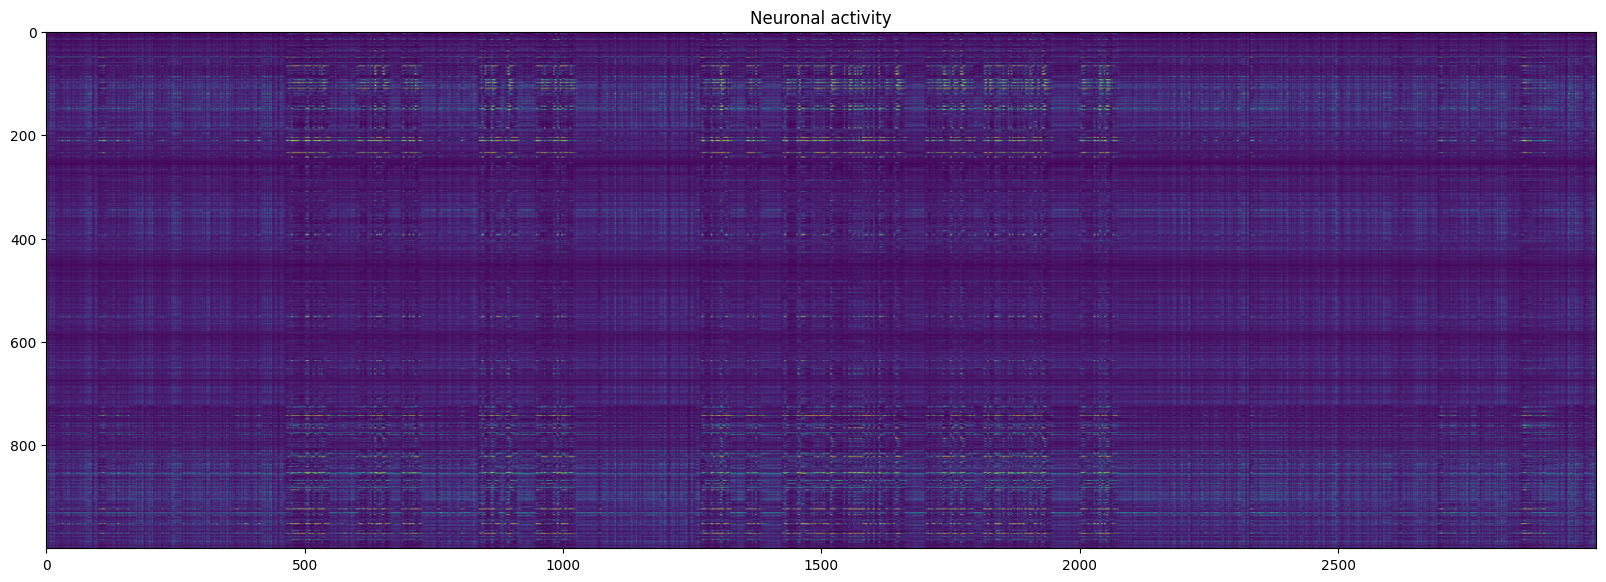

In [11]:
plt.figure(figsize=(20, 20))
plt.imshow(np.clip(recos_manifold[0].values[:3000, :1000].T, 0, 500), cmap='viridis')
plt.title('Neuronal activity')